## Investigation Code for '_A Comparative Analysis of Vision Transformers and Convolutional Neural Networks for Low-Resolution image classification_'
---

## Libraries and Image Processing

In [ ]:
# Import Reququired libraries
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import random
from PIL import Image
import zipfile
from pathlib import Path
import requests

# pip to install libraries that are commonly not present in google collab
!pip install torchinfo torcheval datasets

# Import torch and torchvision libraries
import torch
import torchvision
from torch import nn
from torchvision import datasets, transforms
from torchinfo import summary
from torch.utils.data import DataLoader, random_split, Subset
from torch.optim.lr_scheduler import CosineAnnealingLR

from datasets import load_dataset
from transformers import AutoTokenizer



# CUDA for GPU computations and offloading
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Setting manual seed for reproducibility
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
g = torch.Generator().manual_seed(seed)
random.seed(seed)
np.random.seed(seed)
torch.backends.cudnn.deterministic = True # Make CuDNN deterministic
torch.backends.cudnn.benchmark = False

device

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 4.8 MB/s eta 0:00:00


'cpu'

In [ ]:
# Display hardware information (google collab)
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
# Load dataset to a variable
dataset = load_dataset('timm/resisc45')


# Create seperate train/test/validatiation variables
# NOTE -> These store the location to each database section in memmory, not the
# database itself.
train = len(dataset['train'])
test = len(dataset['test'])
val = len(dataset['validation'])

total_size = train+test+val
print(f'Total Size: {total_size}')
print(f'Train: {train/total_size}')
print(f'Validation: {val/total_size}')
print(f'Testing: {test/total_size}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/255M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/85.1M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/85.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/18900 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Total Size: 31500
Train: 0.6
Validation: 0.2
Testing: 0.2


In [ ]:
# Save class name list
class_names = dataset['train'].features['label'].names
num_classes = len(class_names)

Image tensor shape (C,H,W): (3, 256, 256)


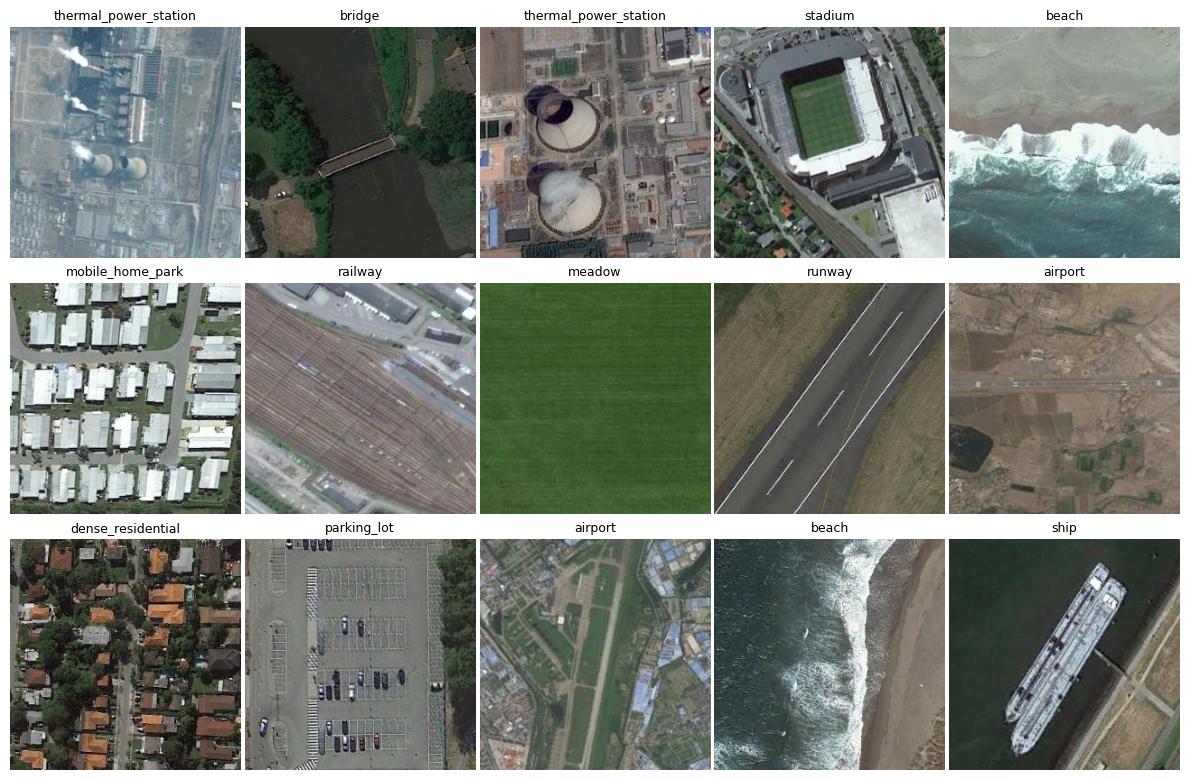

In [ ]:
# Code to display a sample from the dataset

# Select random sample of 15 images from the training dataset
idxs = random.sample(range(len(dataset['train'])), 15)
batch = dataset['train'].select(idxs)

# Pair each selected image with its corresponding label
samples = list(zip(batch['image'], batch['label']))

# Create grid to display the images
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
axes = axes.flatten()

# Transformation to convert from PIL image to pytorch tensor datatype
to_tensor = transforms.ToTensor()
first_shape_printed = False # bool used to print tensor image shape only for first image

# Mapping from label ID to readable label
id2label = dataset['train'].features['label'].int2str

# Iterate over suplot axes and corresponding image:label pairs
for ax, (image, label) in zip(axes, samples):
    # Resize image
    pixels = 256
    img_resized = image.resize((pixels, pixels), resample=Image.BICUBIC)

    # Display resized image
    ax.imshow(img_resized)
    ax.axis('off')
    # Display class names
    ax.set_title(id2label(label), fontsize=9)

    # Print tensor shape for only the first image
    if not first_shape_printed:
        tensor_img = to_tensor(img_resized)
        print('Image tensor shape (C,H,W):', tuple(tensor_img.shape))
        first_shape_printed = True

# Tight layout so that images are placed closer to eachother
plt.tight_layout(w_pad=0.3, h_pad=0.6)
plt.show()


## DataLoader Creation

In [ ]:
# Hyperparameters for dataset creation
BATCH_SIZE = 32
TRAIN_SIZE = 0.64
VAL_SIZE = 0.18
TEST_SIZE = 0.18
NUM_WORKERS = 2

Temporary dataset to find mean and standard deviation of all pixels, used for normalization:

In [ ]:
# Finds mean and standard deviation of pixels for each color channel by iterating
# over a temporary dataloader, as these measures vary with pixel resolution.
def compute_mean_std(train_ds, pixels, batch_size=256, num_workers=2):

    # Transformation to resize and convert input image as tensor
    stats_tfm = transforms.Compose([
        transforms.Resize((pixels, pixels)),
        transforms.ToTensor(),
    ])

   # Transform function applied on the go when loading images from the dataset
    def _stats_transform(batch):
        imgs = [stats_tfm(img.convert('RGB')) for img in batch['image']]
        return {'pixel_values': imgs}

    train_view = train_ds.with_transform(_stats_transform)

    # Custom collate method to return a tensor of format [Batch_size, Color, Height, Width]
    def _collate(batch):
        imgs = [item['pixel_values'] for item in batch]
        return torch.stack(imgs, dim=0)

    # Creates a temporary dataloader to apply custom transforms
    temp_loader = DataLoader(
        train_view,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        collate_fn=_collate
    )

    # Iterating over all images in train loader to find mean/std
    n_pixels = 0
    channel_sum = torch.zeros(3)
    channel_sum_squard = torch.zeros(3)

    with torch.no_grad(): # No gradient tracking as not needed
        for x in temp_loader:
            x = x.float()
            b, c, h, w = x.shape
            n_pixels += b * h * w

            # Sum across, batch, heigh, and width dims
            channel_sum += x.sum(dim=(0, 2, 3))
            channel_sum_squard += (x ** 2).sum(dim=(0, 2, 3))

    # Calculate mean/std
    mean = channel_sum / n_pixels
    var  = channel_sum_squard / n_pixels - mean ** 2
    std  = var.clamp_min(1e-12).sqrt()

    return mean.tolist(), std.tolist()


In [ ]:
# Method to create dataloader at a specified pixel resolution
def create_resisc_dataloader(ds, pixels):
    # Get mean and stdev at res
    mean, stdev = compute_mean_std(dataset['train'], pixels)

    # Transformations applied to training set
    train_transform = transforms.Compose([

        # Resize to pixel dimensions
        transforms.Resize((pixels, pixels)),

        # Data augmentation, only for training dataset
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),

        # Transform into tensor values so that they can be processed by each model
        transforms.ToTensor(),

        # Normalize for improved backpropagation
        transforms.Normalize(mean, stdev)
        ])


    # Transformations applied to testing and validation set
    val_test_transform = transforms.Compose([
        transforms.Resize((pixels, pixels)),
        transforms.ToTensor(),
        transforms.Normalize(mean, stdev)
        ])


    # Applies transform to each image individually rather than the full dataset
    # (transforms would override eachother when applying to the train/val/test sets)
    def make_set_transform(tfm):
        def _transform(batch):
            imgs = [tfm(img.convert('RGB')) for img in batch['image']] # Ensure RGB
            labels = batch['label']
            return {'pixel_values': imgs, 'labels': labels}
        return _transform

    ds['train'].set_transform(make_set_transform(train_transform))
    ds['validation'].set_transform(make_set_transform(val_test_transform))
    ds['test'].set_transform(make_set_transform(val_test_transform))


    # Creating train and test dataloaders split data into batches
    train_dataloader = DataLoader(ds['train'],
                                  batch_size=BATCH_SIZE,
                                  shuffle=True,
                                  num_workers=NUM_WORKERS,
                  # Additional params to speed up training:
                                  pin_memory=True,
                                  persistent_workers=True,
                                  prefetch_factor=4)

    val_dataloader = DataLoader(ds['validation'],
                                batch_size=BATCH_SIZE,
                                num_workers=NUM_WORKERS,
                                pin_memory=True,
                                persistent_workers=True,
                                prefetch_factor=4)

    test_dataloader = DataLoader(ds['test'],
                                batch_size=BATCH_SIZE,
                                num_workers=NUM_WORKERS,
                                pin_memory=True,
                                persistent_workers=True,
                                prefetch_factor=4)


    return train_dataloader, val_dataloader, test_dataloader, mean, stdev

In [ ]:
pixels=64
train_dataloader, val_dataloader, test_dataloader, mean, std = create_resisc_dataloader(
                                                                  ds=dataset, pixels=pixels)

In [ ]:
# Displays a sample image and patch visualization

# Extract image/label from dataloader
batch = next(iter(train_dataloader))
images = batch['pixel_values']
labels = batch['labels']
img = images[0].cpu()
label = int(labels[0])

# Reverse the normalization transform (mean, std) to display the image
mean_t = torch.tensor(mean, dtype=img.dtype).view(3,1,1)
std_t  = torch.tensor(std,  dtype=img.dtype).view(3,1,1)
img = img * std_t + mean_t

# Permute and clip as to fit the matplotlib format
img = img.permute(1, 2, 0).numpy()
img = np.clip(img, 0.0, 1.0)

# Plotting the initial image with matplotlib
plt.figure(figsize=(6,6))
plt.imshow(img)
print(f'Label: {class_names[label]}')
plt.axis('off')
plt.show()


patch_size = 10
H, W, C = img.shape

# Calculate how many patches to display along each axis
n_h = H // patch_size
n_w = W // patch_size

# Plotting 'patched' image
fig, axes = plt.subplots(n_h, n_w, figsize=(n_w, n_h))

# Split image into found patch size
for i in range(n_h):
    for j in range(n_w):
        patch = img[i*patch_size:(i+1)*patch_size,
                    j*patch_size:(j+1)*patch_size, :]
        # Display image patch on corresponding figure location
        axes[i, j].imshow(patch)
        axes[i, j].axis('off')

# Adjust formatting so that images are close together
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

## Training/Valdiation and Testing Loop

In [ ]:
# Additional imports used
from tqdm.auto import tqdm
from time import time
import copy

# Method to automate train and validation loop
def train_val_loop(model, train_dataloader, val_dataloader,
                   optimizer, scheduler,loss_fn, num_epochs, device):

    # Track total training time
    start_time = time()

    # Initialize lists to save metrics
    train_losses, train_accs = [], []
    val_losses, val_accs = [], []
    list_lr = []

    # Keeps track of the highest validation accuracy across all epochs
    best_val_acc = 0.0

    # Insantiate the loss function (same for all models)
    loss_fn_val = nn.CrossEntropyLoss()

    # Loop for a desired number of epochs
    for epoch in tqdm(range(num_epochs)):
        print(f'Epoch: {epoch+1}\n-------')

        ## Training Loop
        model.train() # Set model in training mode
        train_loss, train_correct, train_total = 0.0, 0, 0

        # Iterate over each batch in the training dataloader
        for batch in train_dataloader:
          #  Model Predictions
          X = batch['pixel_values'].to(device, non_blocking=True)
          y = batch['labels'].to(device, non_blocking=True)

          # Do the Forward pass
          y_pred = model(X)

          # Calculate the loss
          loss = loss_fn(y_pred, y)

          # Backpropagation
          optimizer.zero_grad(set_to_none=True)
          loss.backward()
          optimizer.step()

          # Tracking Weighted loss
          batch_size = y.size(0)
          train_loss += loss.item() * batch_size

          # Tracking Accuracy
          preds = y_pred.argmax(dim=1)
          train_correct += (preds == y).sum().item()
          train_total += y.size(0)

        # Average over all samples
        train_loss /= train_total
        train_acc = 100 * train_correct / train_total
        train_losses.append(train_loss)
        train_accs.append(train_acc)


        ## ----- Validation Loop -----
        model.eval() # Set model in evaluation mode
        val_loss, val_correct, val_total = 0.0, 0, 0

        # Disable gradient computation and adds extra optimization (faster)
        with torch.inference_mode():

          # Iterate over each batch in the testing dataloader
          for batch in val_dataloader:
            # Predictions:
            X = batch['pixel_values'].to(device, non_blocking=True),
            y = batch['labels'].to(device, non_blocking=True)

            # Do the forward pass
            val_pred = model(X)
            # Calculate the loss
            loss = loss_fn_val(val_pred, y)

            # Track Weighted Loss
            batch_size = y.size(0)
            val_loss += loss.item() * batch_size

            # Track Accuracy
            preds = val_pred.argmax(dim=1)
            val_correct += (preds == y).sum().item()
            val_total += y.size(0)

        # Average acc/loss over all samples
        val_loss /= val_total
        val_acc = 100 * val_correct / val_total
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        # Saves the model if it performed better than best accuracy
        if best_val_acc < val_acc:
            best_val_acc = val_acc
            best_model = copy.deepcopy(model)

        # Print summary
        print(
            f'\nTrain loss: {train_loss:.5f} | '
            f'Train acc: {train_acc:.2f}% | '
            f'Val loss: {val_loss:.5f} | '
            f'Val acc: {val_acc:.2f}%\n'
        )

        # Adjust learning rate with scheduler
        scheduler.step()

    # Stop timer once training finished
    end_time = time()
    length_time = int(end_time - start_time)

    return best_model, train_losses, val_losses, train_accs, val_accs, length_time

In [ ]:
# Test loop
def test_loop(model, test_dataloader, loss_fn=nn.CrossEntropyLoss(), device=device):

    # Keep track of inference time
    start_time = time()

    # Set model to evaluation mode
    model.eval()

    # Track correct/incorrect predicitons -> used for precision/recall/f1
    test_loss, test_correct, test_total = 0.0, 0, 0
    epoch_preds, epoch_targets = [], []

    with torch.inference_mode():
      # Iterate over test dataloader
      for batch in test_dataloader:

        # Get test predictions
        X = batch['pixel_values'].to(device, non_blocking=True),
        y = batch['labels'].to(device, non_blocking=True)

        # Forward pass
        test_pred = model(X)

        # Calculate loss
        loss = loss_fn(test_pred, y)

        # Track Weighted Loss
        batch_size = y.size(0)
        test_loss += loss.item() * batch_size

        # Track Accuracy
        preds = test_pred.argmax(dim=1)
        test_correct += (preds == y).sum().item()
        test_total += y.size(0)

        # Track Evaluation metrics
        epoch_preds.append(preds.detach().cpu())
        epoch_targets.append(y.detach().cpu())

    # Average over all samples
    test_loss /= test_total
    test_acc = 100 * test_correct / test_total

    # Keep last epochs full set of preds/targets as 1D tensors
    preds_all = torch.cat(epoch_preds, dim=0)
    targets_all = torch.cat(epoch_targets, dim=0)

    # Find average time for 1 image to be classified
    end_time = time()
    num_images_seen = len(test_dataloader.dataset)
    avg_inference_time = round(((end_time - start_time) / num_images_seen), 2)

    return test_loss, test_acc, preds_all, targets_all, avg_inference_time

In [ ]:
# Helper method to plot train results
def plot_train_results(model_name, model_train_results, pixels):

    # Plotting Training and Testing Accuracy / Loss
    plt.figure(figsize=(12, 5))
    plt.suptitle(f'{model_name} @ {str(pixels)}x{str(pixels)} pixels', fontsize=16, y=1.02)

    # Loss Graph
    plt.subplot(1, 2, 1)
    plt.plot(range(num_epochs), model_train_results[1], label='Train Loss')
    plt.plot(range(num_epochs), model_train_results[2], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.title('Loss')
    plt.legend()
    ax.set_ylim(0, 1)


    # Accuracy Graph
    plt.subplot(1, 2, 2)
    plt.plot(range(num_epochs), model_train_results[3], label='Train Accuracy')
    plt.plot(range(num_epochs), model_train_results[4], label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.title('Accuracy')
    plt.legend()
    ax.set_ylim(65, 100)

    print(f'Model training time: {model_train_results[5]} seconds')

    # Display graphs
    plt.show()

## Model Hyperparameter Tuning With Training/Validation Graphs

In [ ]:
# Set number of epochs to train for (same across all models)
num_epochs=20

#### ResNet18

11.7M Parameters

In [ ]:
# ResNet-18 Hyperparameters
lr=5e-2
momentum=0.9
wd=1e-4

# Creating the model
resnet18 = torchvision.models.resnet18(weights=None)

## MODEL MODIFICATIONS
# Prevents the model from shrinking the image mapping too early on
resnet18.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
resnet18.maxpool = nn.Identity()

# Replaces the final fully connected layer output from 1000 classes to 47 classes (Imagenet1k -> Resisc45)
in_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(in_features, num_classes)
resnet18 = resnet18.to(device)

# Loss Function to calculate the loss
loss_fn_res = nn.CrossEntropyLoss(label_smoothing=0.1)

# Optimizer to update the weights after finding gradients
optimizer_res = torch.optim.SGD(resnet18.parameters(), lr=lr, weight_decay=wd)

# Scheduler decreases lr from max to 1e-6 at Cosin for epoch
scheduler_res = CosineAnnealingLR(optimizer_res, T_max=num_epochs, eta_min=1e-6)

In [ ]:
# (optional) summary of architecture structure
summary(model=resnet18,
        input_size=(64, 3, pixels, pixels),
        col_names=['input_size', 'output_size', 'num_params', 'trainable'],
        col_width=20,
        row_settings=['var_names'])

In [ ]:
# Training and evaluating ResNet18
resnet18_train_results = train_val_loop(model=resnet18,
                                        train_dataloader=train_dataloader,
                                        val_dataloader=val_dataloader,
                                        optimizer=optimizer_res,
                                        scheduler=scheduler_res,
                                        loss_fn=loss_fn_res,
                                        num_epochs=num_epochs,
                                        device=device)

In [ ]:
# Plot train graphs
plot_train_results(model_name='ResNet18', model_train_results=resnet18_train_results, pixels=pixels)

#### ResNet50

25M Parameters

In [ ]:
# ResNet-50 Hyperparameters
lr=5e-2
momentum=0.9
wd=1e-4


# Creating the model
resnet50 = torchvision.models.resnet50(weights=None)

## MODEL MODIFICATIONS
resnet50.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
resnet50.maxpool = nn.Identity()
resnet50 = resnet50.to(device)
in_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(in_features, num_classes)
resnet50 = resnet50.to(device)


loss_fn_res = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_res = torch.optim.SGD(resnet50.parameters(), lr=lr, weight_decay=wd)
scheduler_res = CosineAnnealingLR(optimizer_res, T_max=num_epochs, eta_min=1e-6)

In [ ]:
summary(model=resnet18,
        input_size=(64, 3, pixels, pixels),
        col_names=['input_size', 'output_size', 'num_params', 'trainable'],
        col_width=20,
        row_settings=['var_names'])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [64, 3, 64, 64]      [64, 45]             --                   True
├─Conv2d (conv1)                         [64, 3, 64, 64]      [64, 64, 64, 64]     1,728                True
├─BatchNorm2d (bn1)                      [64, 64, 64, 64]     [64, 64, 64, 64]     128                  True
├─ReLU (relu)                            [64, 64, 64, 64]     [64, 64, 64, 64]     --                   --
├─Identity (maxpool)                     [64, 64, 64, 64]     [64, 64, 64, 64]     --                   --
├─Sequential (layer1)                    [64, 64, 64, 64]     [64, 64, 64, 64]     --                   True
│    └─BasicBlock (0)                    [64, 64, 64, 64]     [64, 64, 64, 64]     --                   True
│    │    └─Conv2d (conv1)               [64, 64, 64, 64]     [64, 64, 64, 64]     36,864               True
│    │    └─BatchN

In [ ]:
# Training and evaluating ResNet50
resnet50_train_results = train_val_loop(model=resnet50,
                                        train_dataloader=train_dataloader,
                                        val_dataloader=val_dataloader,
                                        optimizer=optimizer_res,
                                        scheduler=scheduler_res,
                                        loss_fn=loss_fn_res,
                                        num_epochs=num_epochs,
                                        device=device)

In [ ]:
plot_train_results(model_name='ResNet50', model_train_results=resnet50_train_results)

#### ViT Small
21M Parameters

In [ ]:
# ViT-Tiny Hyperparameters
lr=1e-4
wd=5e-2

# Dropout to randomly deactivate classification/attention heads so that each module doesn't
# memorize adaptation patterns, and can adapt to unseen data
dropout = 0.1
head_dropout=0.3
attn_dropout=0.1


# Creating the model, source: https://dailyai.github.io/2021-06-21/2106-10270
vit_small = torchvision.models.VisionTransformer(image_size=pixels, patch_size=8,
                                                num_layers=12, num_heads=6,
                                                hidden_dim=384, mlp_dim=1536,
                                                num_classes=num_classes,
                                                dropout=dropout, attention_dropout=attn_dropout)

in_features = vit_small.heads.head.in_features
vit_small.heads.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(in_features, num_classes))
vit_small.to(device)


# Loss function, Optimizer, Scheduler
loss_fn_vit = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_vit = torch.optim.AdamW(vit_small.parameters(), lr=lr, weight_decay=wd)
scheduler_vit = CosineAnnealingLR(optimizer_vit, T_max=num_epochs, eta_min=1e-6)

In [ ]:
summary(model=vit_small,
        input_size=(64, 3, pixels, pixels),
        col_names=['input_size', 'output_size', 'num_params', 'trainable'],
        col_width=20,
        row_settings=['var_names'])

In [ ]:
# Training and evaluating ResNet50
vit_small_train_results = train_val_loop(model=vit_small,
                                        train_dataloader=train_dataloader,
                                        val_dataloader=test_dataloader,
                                        optimizer=optimizer_vit,
                                        scheduler=scheduler_vit,
                                        loss_fn=loss_fn_vit,
                                        num_epochs=num_epochs,
                                        device=device)

In [ ]:
plot_train_results(model_name='ViT-Tiny', model_train_results=vit_small_train_results, pixels=pixels)

#### ViT Base
85M Parameters

In [ ]:
# ViT-Base Hyperparameters
lr=1e-4
wd=5e-2
dropout = 0.1
head_dropout=0.3
attn_dropout=0.1


# Creating the model
vit_base = torchvision.models.VisionTransformer(image_size=pixels,
                                                patch_size=8,
                                                num_layers=12,
                                                num_heads=12,
                                                hidden_dim=768,
                                                mlp_dim=3072,
                                                num_classes=num_classes,
                                                dropout=dropout, attention_dropout=attn_dropout)


in_features = vit_base.heads.head.in_features
vit_base.heads.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(in_features, num_classes))
vit_base.to(device)

# Loss function, Optimizer, Scheduler
loss_fn_vit = nn.CrossEntropyLoss()
optimizer_vit = torch.optim.AdamW(vit_base.parameters(), lr=lr, weight_decay=wd)
scheduler_vit = CosineAnnealingLR(optimizer_vit, T_max=num_epochs, eta_min=1e-6)

In [ ]:
summary(model=vit_base,
        input_size=(64, 3, pixels, pixels),
        col_names=['input_size', 'output_size', 'num_params', 'trainable'],
        col_width=20,
        row_settings=['var_names'])

In [ ]:
# Training and evaluating ResNet50
vit_base_train_results = train_val_loop(model=vit_base,
                                        train_dataloader=train_dataloader,
                                        val_dataloader=test_dataloader,
                                        optimizer=optimizer_vit,
                                        scheduler=scheduler_vit,
                                        loss_fn=loss_fn_vit,
                                        num_epochs=num_epochs,
                                        device=device)

In [ ]:
plot_train_results(model_name='ViT-Base', model_train_results=vit_base_train_results, pixels=pixels)

## Model Training for Pixel Range

In [ ]:
pixels_list = [32, 64, 128]
results_dict={} # Save models + results table
test_dataloaders = []
num_epochs=20

# Iterate over all resolutions
for px in pixels_list:

    ## Creating Dataloaders at the iteration's resolution
    train_dataloader, val_dataloader, test_dataloader, mean, std = create_resisc_dataloader(pixels=px)


    ## ResNet Hyperparameters
    lr=5e-2
    momentum=0.9
    wd=1e-4

     ## RESNET18

    resnet18 = torchvision.models.resnet18(weights=None)
    resnet18.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    resnet18.maxpool = nn.Identity()

    in_features = resnet18.fc.in_features
    resnet18.fc = nn.Linear(in_features, num_classes)
    resnet18 = resnet18.to(device)

    loss_fn_res = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_res = torch.optim.SGD(resnet18.parameters(), lr=lr, weight_decay=wd, momentum=momentum)
    scheduler_res = CosineAnnealingLR(optimizer_res, T_max=num_epochs, eta_min=1e-6)

    resnet18_train_results = train_val_loop(model=resnet18,
                                            train_dataloader=train_dataloader,
                                            val_dataloader=val_dataloader,
                                            optimizer=optimizer_res,
                                            scheduler=scheduler_res,
                                            loss_fn=loss_fn_res,
                                            num_epochs=num_epochs,
                                            device=device)

    results_dict['resnet18-'+str(px)] = resnet18_train_results

    ## RESNET50

    resnet50 = torchvision.models.resnet50(weights=None)
    resnet50.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    resnet50.maxpool = nn.Identity()
    in_features = resnet50.fc.in_features
    resnet50.fc = nn.Linear(in_features, num_classes)
    resnet50 = resnet50.to(device)


    loss_fn_res = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_res = torch.optim.SGD(resnet50.parameters(), lr=lr, weight_decay=wd, momentum=momentum)
    scheduler_res = CosineAnnealingLR(optimizer_res, T_max=num_epochs, eta_min=1e-6)

    resnet50_train_results = train_val_loop(model=resnet50,
                                            train_dataloader=train_dataloader,
                                            val_dataloader=val_dataloader,
                                            optimizer=optimizer_res,
                                            scheduler=scheduler_res,
                                            loss_fn=loss_fn_res,
                                            num_epochs=num_epochs,
                                            device=device)

    results_dict['resnet50-'+str(px)] = resnet50_train_results

    ## ViT-SMALL
    lr=1e-4
    wd=5e-2
    dropout = 0.1
    head_dropout=0.3
    attn_dropout=0.1


    vit_small = torchvision.models.VisionTransformer(image_size=px, patch_size=8,
                                                    num_layers=12, num_heads=6,
                                                    hidden_dim=384, mlp_dim=1536,
                                                    num_classes=num_classes,
                                                    dropout=dropout, attention_dropout=attn_dropout)

    in_features = vit_small.heads.head.in_features
    vit_small.heads.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(in_features, num_classes))
    vit_small.to(device)

    loss_fn_vit = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_vit = torch.optim.AdamW(vit_small.parameters(), lr=lr, weight_decay=wd)
    scheduler_vit = CosineAnnealingLR(optimizer_vit, T_max=num_epochs, eta_min=1e-6)

    vit_small_train_results = train_val_loop(model=vit_small,
                                            train_dataloader=train_dataloader,
                                            val_dataloader=val_dataloader,
                                            optimizer=optimizer_vit,
                                            scheduler=scheduler_vit,
                                            loss_fn=loss_fn_vit,
                                            num_epochs=num_epochs,
                                            device=device)

    results_dict['vitsmall-'+str(px)] = vit_small_train_results

    ## VIT-BASE
    vit_base = torchvision.models.VisionTransformer(image_size=px, patch_size=8,
                                                    num_layers=12, num_heads=12,
                                                    hidden_dim=768, mlp_dim=3072,
                                                    num_classes=num_classes,dropout=dropout, attention_dropout=attn_dropout)

    in_features = vit_base.heads.head.in_features
    vit_base.heads.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(in_features, num_classes))
    vit_base.to(device)

    loss_fn_vit = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_vit = torch.optim.AdamW(vit_base.parameters(), lr=lr, weight_decay=wd)
    scheduler_vit = CosineAnnealingLR(optimizer_vit, T_max=num_epochs, eta_min=1e-6)

    vit_base_train_results = train_val_loop(model=vit_base,
                                            train_dataloader=train_dataloader,
                                            val_dataloader=val_dataloader,
                                            optimizer=optimizer_vit,
                                            scheduler=scheduler_vit,
                                            loss_fn=loss_fn_vit,
                                            num_epochs=num_epochs,
                                            device=device)

    results_dict['vitbase-'+str(px)] = vit_base_train_results
    test_dataloaders.append(test_dataloader)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1
-------

Train loss: 3.20322 | Train acc: 17.95% | Val loss: 2.59246 | Val acc: 27.51%

Epoch: 2
-------

Train loss: 2.70434 | Train acc: 30.81% | Val loss: 2.04991 | Val acc: 42.00%

Epoch: 3
-------

Train loss: 2.40854 | Train acc: 40.62% | Val loss: 2.04095 | Val acc: 41.73%

Epoch: 4
-------

Train loss: 2.19656 | Train acc: 47.83% | Val loss: 1.82665 | Val acc: 46.11%

Epoch: 5
-------

Train loss: 2.00248 | Train acc: 55.23% | Val loss: 1.47974 | Val acc: 57.89%

Epoch: 6
-------

Train loss: 1.82698 | Train acc: 61.11% | Val loss: 1.27059 | Val acc: 63.24%

Epoch: 7
-------

Train loss: 1.66806 | Train acc: 66.69% | Val loss: 1.10309 | Val acc: 67.56%

Epoch: 8
-------

Train loss: 1.54141 | Train acc: 70.85% | Val loss: 0.98896 | Val acc: 71.68%

Epoch: 9
-------

Train loss: 1.43961 | Train acc: 74.62% | Val loss: 0.94493 | Val acc: 73.03%

Epoch: 10
-------

Train loss: 1.35863 | Train acc: 78.17% | Val loss: 0.90470 | Val acc: 73.62%

Epoch: 11
-------

Train loss

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1
-------

Train loss: 4.05107 | Train acc: 5.43% | Val loss: 3.40231 | Val acc: 8.67%

Epoch: 2
-------

Train loss: 3.43247 | Train acc: 10.30% | Val loss: 3.20521 | Val acc: 14.00%

Epoch: 3
-------

Train loss: 3.23324 | Train acc: 15.76% | Val loss: 3.04468 | Val acc: 16.71%

Epoch: 4
-------

Train loss: 3.03323 | Train acc: 20.81% | Val loss: 2.58962 | Val acc: 25.94%

Epoch: 5
-------

Train loss: 2.82632 | Train acc: 27.01% | Val loss: 2.35310 | Val acc: 32.03%

Epoch: 6
-------

Train loss: 2.65144 | Train acc: 32.70% | Val loss: 2.13028 | Val acc: 38.24%

Epoch: 7
-------

Train loss: 2.46873 | Train acc: 38.46% | Val loss: 2.17176 | Val acc: 40.33%

Epoch: 8
-------

Train loss: 2.33066 | Train acc: 42.67% | Val loss: 1.76091 | Val acc: 48.97%

Epoch: 9
-------

Train loss: 2.18459 | Train acc: 48.11% | Val loss: 1.64066 | Val acc: 53.57%

Epoch: 10
-------

Train loss: 2.08216 | Train acc: 51.68% | Val loss: 1.50812 | Val acc: 56.76%

Epoch: 11
-------

Train loss: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1
-------

Train loss: 3.11497 | Train acc: 20.23% | Val loss: 2.50180 | Val acc: 30.59%

Epoch: 2
-------

Train loss: 2.70379 | Train acc: 31.56% | Val loss: 2.26198 | Val acc: 36.41%

Epoch: 3
-------

Train loss: 2.50152 | Train acc: 37.70% | Val loss: 2.08293 | Val acc: 40.56%

Epoch: 4
-------

Train loss: 2.36306 | Train acc: 42.03% | Val loss: 2.02937 | Val acc: 41.89%

Epoch: 5
-------

Train loss: 2.25070 | Train acc: 45.69% | Val loss: 1.81950 | Val acc: 47.56%

Epoch: 6
-------

Train loss: 2.14554 | Train acc: 49.03% | Val loss: 1.76183 | Val acc: 49.62%

Epoch: 7
-------

Train loss: 2.05465 | Train acc: 52.29% | Val loss: 1.61938 | Val acc: 53.30%

Epoch: 8
-------

Train loss: 1.97670 | Train acc: 54.63% | Val loss: 1.58853 | Val acc: 54.37%

Epoch: 9
-------

Train loss: 1.89662 | Train acc: 57.72% | Val loss: 1.55166 | Val acc: 55.76%

Epoch: 10
-------

Train loss: 1.82424 | Train acc: 59.87% | Val loss: 1.53467 | Val acc: 55.67%

Epoch: 11
-------

Train loss

... (14 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1
-------

Train loss: 2.88309 | Train acc: 26.50% | Val loss: 2.03901 | Val acc: 42.52%

Epoch: 2
-------

Train loss: 2.29934 | Train acc: 44.53% | Val loss: 1.71986 | Val acc: 51.29%

Epoch: 3
-------

Train loss: 2.03411 | Train acc: 53.05% | Val loss: 1.42006 | Val acc: 59.48%

Epoch: 4
-------

Train loss: 1.86805 | Train acc: 58.53% | Val loss: 1.37376 | Val acc: 60.83%

Epoch: 5
-------

Train loss: 1.73763 | Train acc: 62.99% | Val loss: 1.22106 | Val acc: 65.14%

Epoch: 6
-------

Train loss: 1.63999 | Train acc: 66.17% | Val loss: 1.13703 | Val acc: 67.44%

Epoch: 7
-------

Train loss: 1.53688 | Train acc: 70.16% | Val loss: 1.05580 | Val acc: 68.73%

Epoch: 8
-------

Train loss: 1.45176 | Train acc: 72.97% | Val loss: 1.10901 | Val acc: 67.76%

Epoch: 9
-------

Train loss: 1.37094 | Train acc: 76.19% | Val loss: 0.97385 | Val acc: 71.37%

Epoch: 10
-------

Train loss: 1.29779 | Train acc: 78.90% | Val loss: 0.91881 | Val acc: 73.56%

Epoch: 11
-------

Train loss

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1
-------

Train loss: 2.87680 | Train acc: 27.78% | Val loss: 1.99397 | Val acc: 42.76%

Epoch: 2
-------

Train loss: 2.26912 | Train acc: 45.36% | Val loss: 1.68403 | Val acc: 50.97%

Epoch: 3
-------

Train loss: 2.01845 | Train acc: 53.53% | Val loss: 1.48968 | Val acc: 56.86%

Epoch: 4
-------

Train loss: 1.83142 | Train acc: 60.33% | Val loss: 1.32429 | Val acc: 60.97%

Epoch: 5
-------

Train loss: 1.70878 | Train acc: 63.86% | Val loss: 1.30695 | Val acc: 61.84%

Epoch: 6
-------

Train loss: 1.59986 | Train acc: 67.59% | Val loss: 1.11122 | Val acc: 67.41%

Epoch: 7
-------

Train loss: 1.50219 | Train acc: 71.03% | Val loss: 1.07962 | Val acc: 68.70%

Epoch: 8
-------

Train loss: 1.40743 | Train acc: 74.54% | Val loss: 1.03320 | Val acc: 69.87%

Epoch: 9
-------

Train loss: 1.32074 | Train acc: 77.74% | Val loss: 1.02484 | Val acc: 70.81%

Epoch: 10
-------

Train loss: 1.23514 | Train acc: 80.70% | Val loss: 0.93321 | Val acc: 73.67%

Epoch: 11
-------

Train loss

In [ ]:
# Download results table
from google.colab import drive

drive.mount('/content/drive')
for model_name, result_table in results_dict.items():
    save_path = f'/content/drive/MyDrive/ViT-CNN-Results/{model_name}_results.pth'
    torch.save(result_table, save_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Comparing Training / Validation Graphs

Display all train/validation of each model grouped by model:

Model training time: 307 seconds


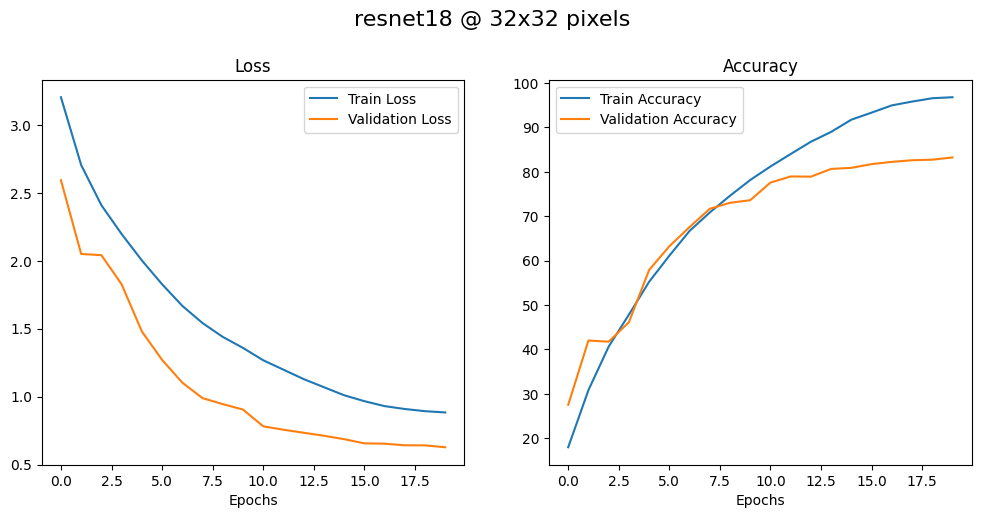

Model training time: 354 seconds


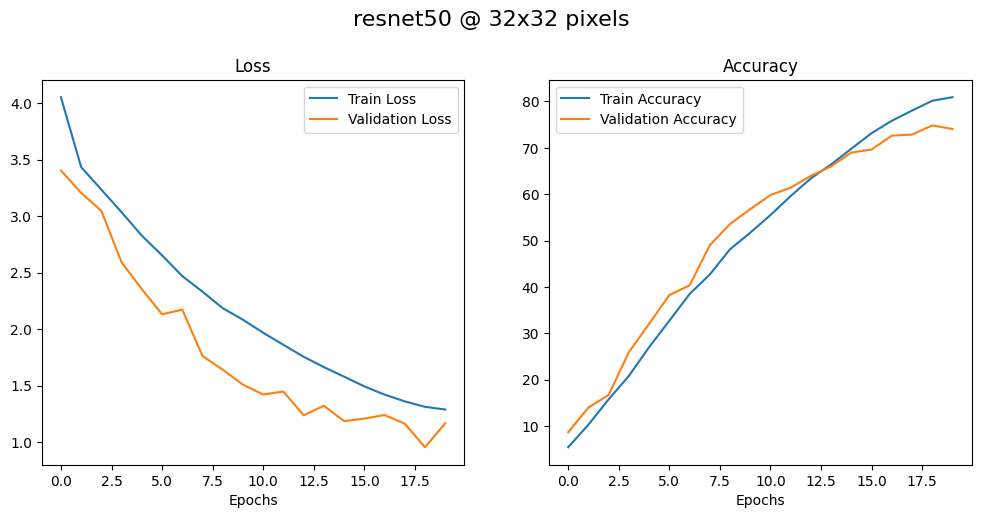

Model training time: 455 seconds


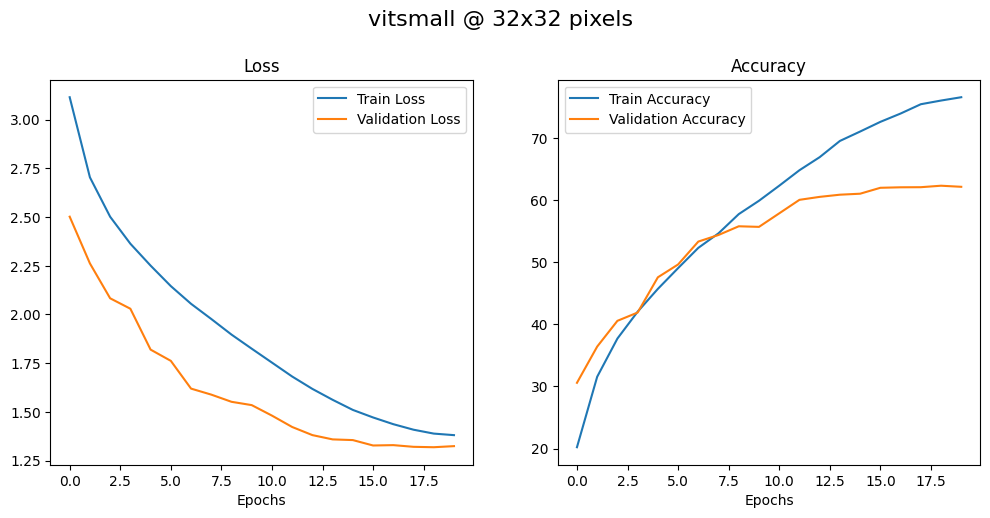

Model training time: 499 seconds


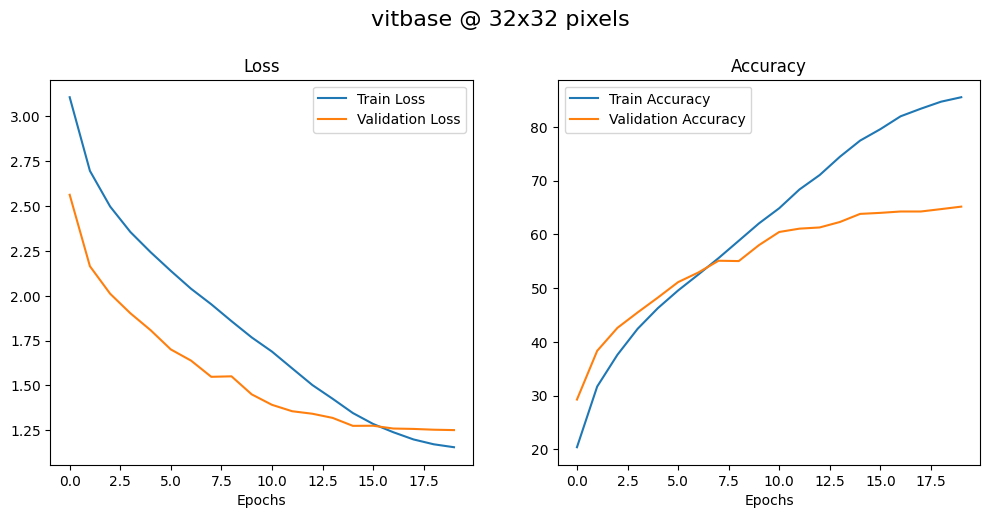

Model training time: 353 seconds


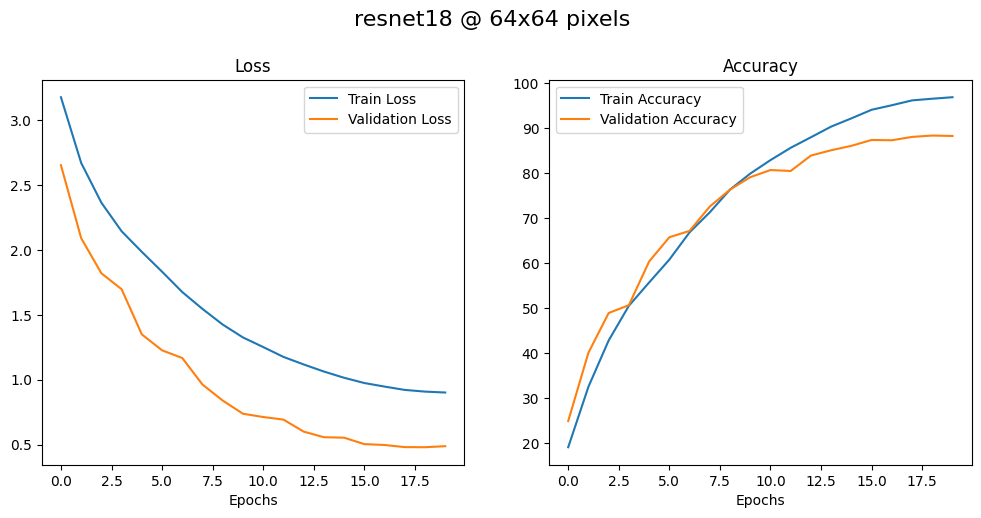

Model training time: 609 seconds


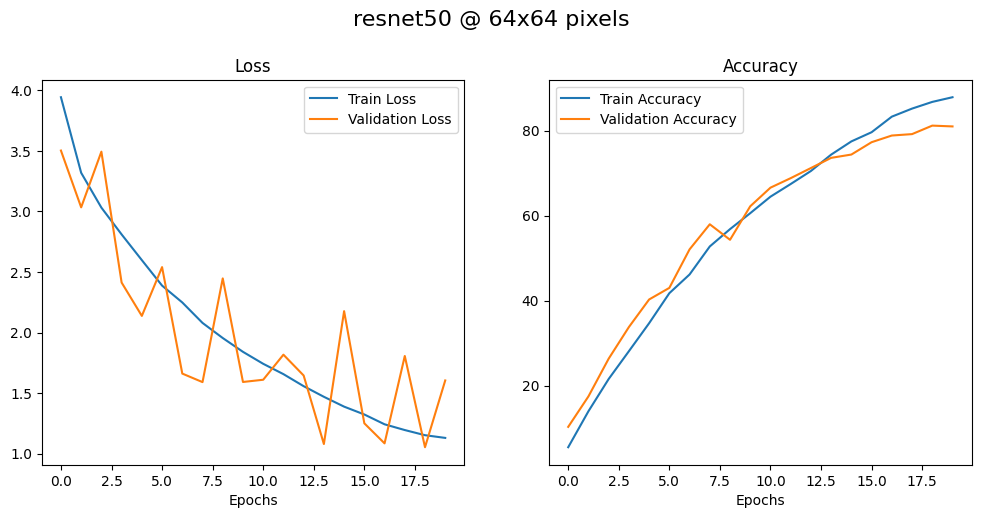

Model training time: 475 seconds


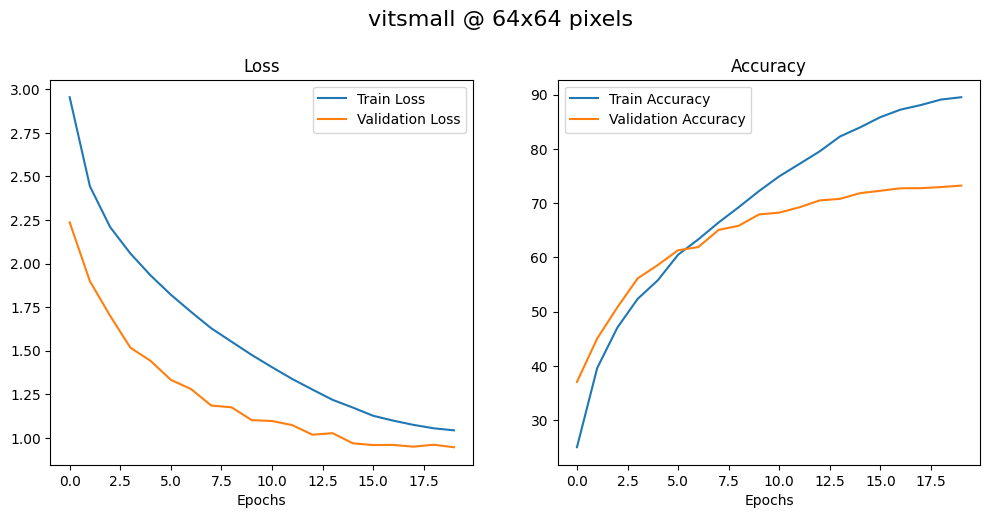

Model training time: 1077 seconds


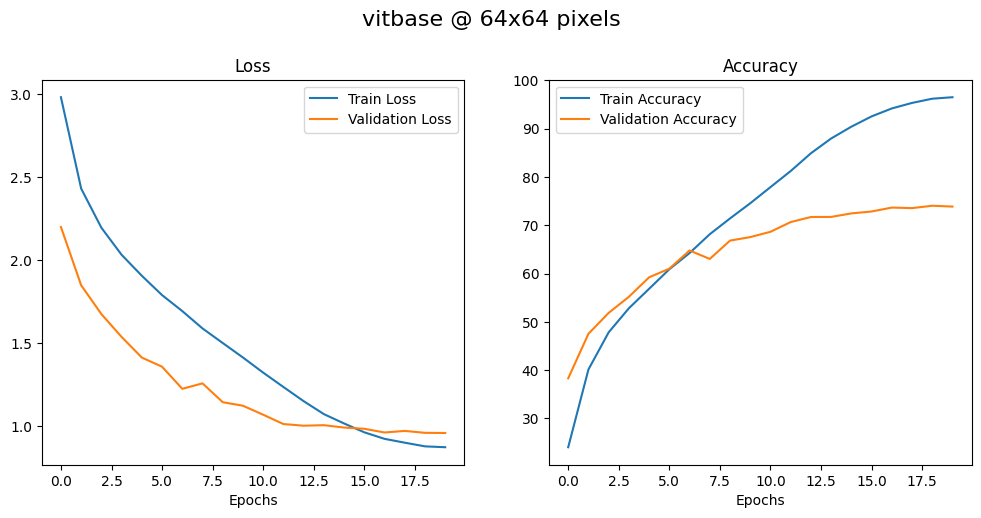

Model training time: 687 seconds


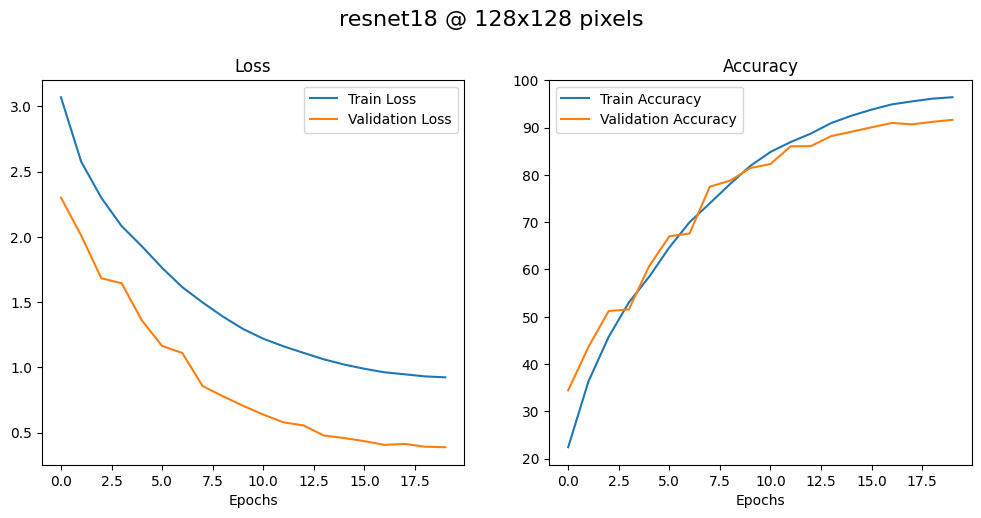

Model training time: 2087 seconds


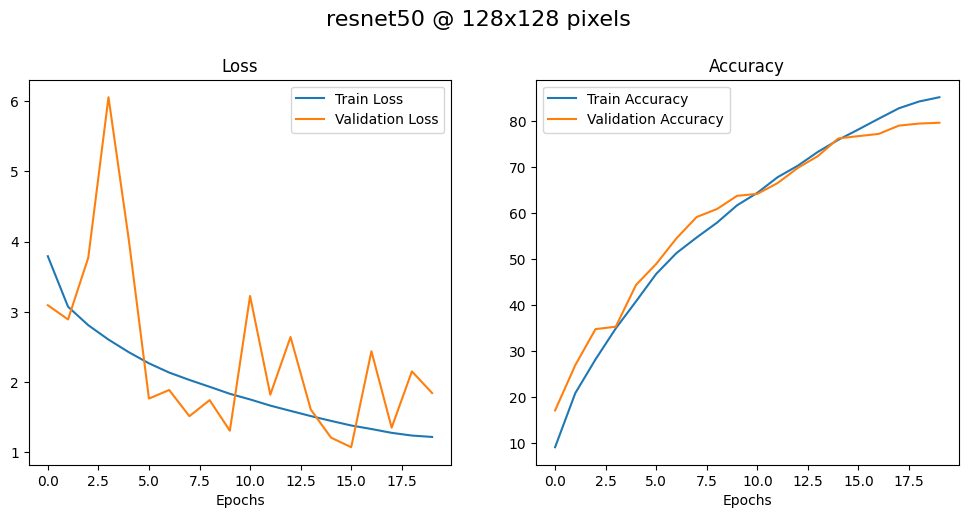

Model training time: 1305 seconds


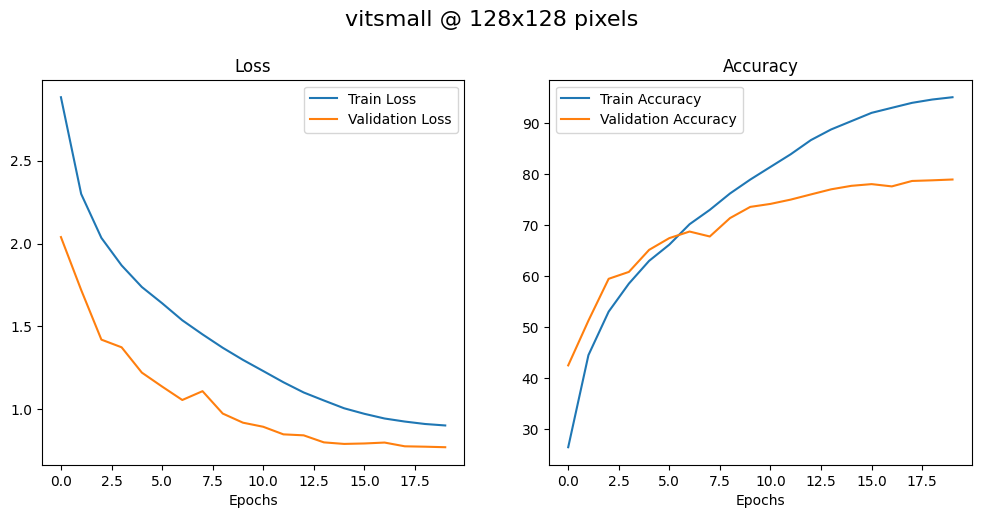

Model training time: 3952 seconds


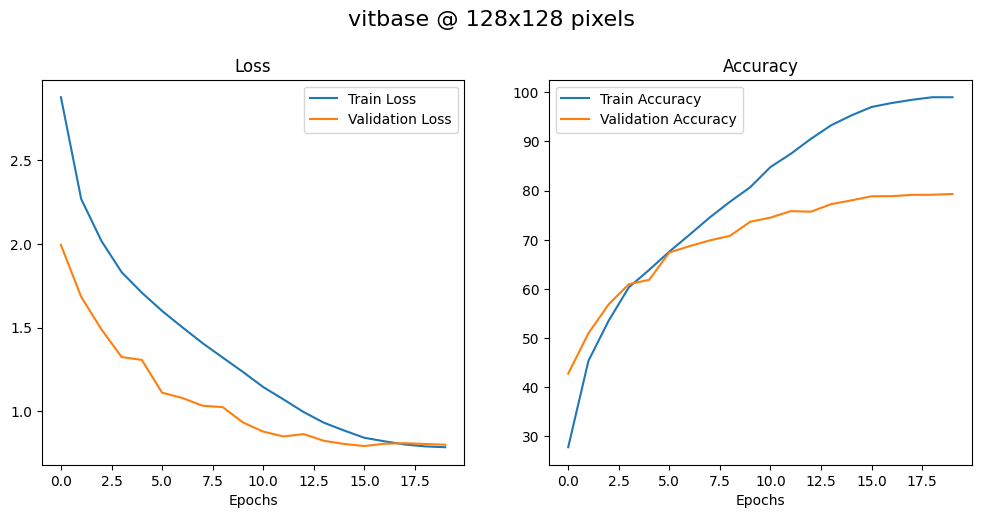

In [ ]:
for model_px_name, result_table in results_dict.items():
    model_name, pixels = model_px_name.split('-')
    plot_train_results(model_name=model_name, model_train_results=result_table, pixels=pixels)

## Model Testing and Evaluation

In [2]:
# Imports
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import torchvision
from torch import nn
from torchvision import transforms
import random
from torch.utils.data import DataLoader


# MPS allows PyTorch to use the M chips in macs for faster computations, similar to CUDA
device = 'mps' if torch.mps.is_available() else 'cpu'

# Setting manual seed for reproducibility
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
g = torch.Generator().manual_seed(seed)
random.seed(seed)
np.random.seed(seed)
torch.backends.cudnn.deterministic = True # Make CuDNN deterministic
torch.backends.cudnn.benchmark = False

In [3]:
# Load the dataset
from datasets import load_dataset
dataset = load_dataset('timm/resisc45')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Get class names
class_names = dataset['train'].features['label'].names
num_classes = len(class_names)

In [5]:
# Hyperparameters for dataset creation
BATCH_SIZE = 32
TRAIN_SIZE = 0.64
VAL_SIZE = 0.18
TEST_SIZE = 0.18

# Finds mean and standard deviation of pixels for each color channel by iterating over a temporary dataloader.

def compute_mean_std(train_ds, pixels, batch_size=256, num_workers=0):
    stats_tfm = transforms.Compose([
        transforms.Resize((pixels, pixels)),
        transforms.ToTensor(),
    ])

    # create a transformed view
    def _stats_transform(batch):
        imgs = [stats_tfm(img.convert('RGB')) for img in batch['image']]
        return {'pixel_values': imgs}
    train_view = train_ds.with_transform(_stats_transform)

    # a simple collate so we get a tensor [B, C, H, W]
    def _collate(batch):
        imgs = [item['pixel_values'] for item in batch]
        return torch.stack(imgs, dim=0)

    loader = DataLoader(
        train_view,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        collate_fn=_collate
    )

    n_pixels = 0
    channel_sum = torch.zeros(3)
    channel_sum_sq = torch.zeros(3)

    with torch.no_grad():
        for x in loader: # x: [B,3,H,W]
            x = x.float()
            b, c, h, w = x.shape
            n_pixels += b * h * w
            channel_sum    += x.sum(dim=(0, 2, 3))
            channel_sum_sq += (x ** 2).sum(dim=(0, 2, 3))

    mean = channel_sum / n_pixels
    var  = channel_sum_sq / n_pixels - mean ** 2
    std  = var.clamp_min(1e-12).sqrt()

    return mean.tolist(), std.tolist()

def create_resisc_dataloader(base_dataset, pixels):
    mean, stdev = compute_mean_std(dataset['train'], pixels)

    ds = base_dataset.with_transform(lambda x: x)

    # Transformations applied to training set
    train_transform = transforms.Compose([
        # Resize to pixel dimensions
        transforms.Resize((pixels, pixels)),

        # Data augmentation, only for training
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),

        # Transform into tensor values
        transforms.ToTensor(),

        # Normalize for improved backpropagation
        transforms.Normalize(mean, stdev)
        ])


    # Transformations applied to testing and validation set
    val_test_transform = transforms.Compose([
        transforms.Resize((pixels, pixels)),
        transforms.ToTensor(),
        transforms.Normalize(mean, stdev)
        ])


    # Applies transform to each image set
    def make_set_transform(tfm):
        def _transform(batch):
            imgs = [tfm(img.convert('RGB')) for img in batch['image']]
            labels = batch['label']
            return {'pixel_values': imgs, 'labels': labels}
        return _transform

    ds['train'].set_transform(make_set_transform(train_transform))
    ds['validation'].set_transform(make_set_transform(val_test_transform))
    ds['test'].set_transform(make_set_transform(val_test_transform))


    # Creating train and test dataloaders split data into batches
    train_dataloader = DataLoader(ds['train'],
                                  batch_size=BATCH_SIZE,
                                  shuffle=True)

    val_dataloader = DataLoader(ds['validation'],
                                batch_size=BATCH_SIZE)

    test_dataloader = DataLoader(ds['test'],
                                batch_size=BATCH_SIZE)


    return train_dataloader, val_dataloader, test_dataloader, mean, stdev

In [6]:
from torch.serialization import add_safe_globals

# Safe globals whitelists these classes, essentially telling PyTorch that the models are safe to deserealize
add_safe_globals([
    torchvision.models.resnet.ResNet,
    torchvision.models.vision_transformer.VisionTransformer,
])

models = ['resnet18','resnet50','vitsmall', 'vitbase']
pixels_list = [32, 64, 128]
results_dict = {}

# Loading all models and training results from the downloaded file
for i in models:
    for j in pixels_list:
        results_dict[i+'-'+str(j)] = torch.load(f'ViT-CNN-Results/{i}-{j}_results.pth',  map_location=device, weights_only=False)

In [15]:
test_dataloaders = []
for px in [32, 64, 128]:
    train_loader, val_loader, test_loader, mean, stdev = create_resisc_dataloader(dataset, px)
    test_dataloaders.append(test_loader)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


KeyboardInterrupt: 

In [ ]:
from torcheval.metrics.functional import (
    multiclass_precision,
    multiclass_recall,
    multiclass_f1_score
)


# Method that calculates all evaluation metrics
def evaluation_metrics(predictions: torch.Tensor, actual: torch.Tensor, num_classes: int):

    # Bring tensors on CPU convert to long
    predictions = predictions.detach().to('cpu').long().flatten()
    actual = actual.detach().to('cpu').long().flatten()

     # Calculating global weighted average metrics -> Weighted accounts for class size imbalances
    precision = multiclass_precision(predictions, actual, average='weighted', num_classes=num_classes)
    recall = multiclass_recall(predictions, actual, average='weighted', num_classes=num_classes)
    f1 = multiclass_f1_score(predictions, actual, average='weighted', num_classes=num_classes)

    return  precision, recall, f1

In [9]:
num_epochs = 20

In [ ]:
from time import time

# Test loop
def test_loop(model, test_dataloader, loss_fn=nn.CrossEntropyLoss(), device=device):

    # Keep track of inference time
    start_time = time()
    
    model.eval() # Model in evaluation mode

    # Keep track of correct/incorrect predicitons
    test_loss, test_correct, test_total = 0.0, 0, 0
    epoch_preds, epoch_targets = [], []

    with torch.inference_mode():
      # Iterate over test dataloader
      for batch in test_dataloader:
        
        # Get test predictions
        X, y = batch['pixel_values'].to(device, non_blocking=True), batch['labels'].to(device, non_blocking=True)

        # Forward pass
        test_pred = model(X)

        # Calculate loss
        loss = loss_fn(test_pred, y)

        # Track Weighted Loss
        batch_size = y.size(0)
        test_loss += loss.item() * batch_size

        # Track Accuracy
        preds = test_pred.argmax(dim=1)
        test_correct += (preds == y).sum().item()
        test_total += y.size(0)

        # Track Evaluation metrics
        epoch_preds.append(preds.detach().cpu())
        epoch_targets.append(y.detach().cpu())

    # Average over all samples
    test_loss /= test_total
    test_acc = 100 * test_correct / test_total

    # Keep last epochs full set of preds/targets as 1D tensors
    preds_all = torch.cat(epoch_preds, dim=0)
    targets_all = torch.cat(epoch_targets, dim=0)

    # Find average time for 1 image to be classified
    end_time = time()
    num_images_seen = len(test_dataloader.dataset)
    avg_inference_time = round(((end_time - start_time) / num_images_seen), 2)

    return test_loss, test_acc, preds_all, targets_all, avg_inference_time

In [ ]:
epochs = np.arange(1, num_epochs + 1)

# Table to save testing results
test_table = {}

# Dictionary of testing accuracies grouped by model architecture
architecture_accs = {'resnet18':[], 'resnet50':[], 'vitsmall':[], 'vitbase':[]}
performance_summary_table = []

# Iterate through results table to extract best performing models, and test them on the testing dataloader
for i, (model_px_name, result_table) in enumerate(results_dict.items()):

    model_name, model_px = model_px_name.split('-')
    test_table[model_px_name] = test_loop(model=result_table[0], test_dataloader=test_dataloaders[i%3], device=device)

    # Performance summary
    num_params = sum(p.numel() for p in result_table[0].parameters())
    precision, recall, f1 = evaluation_metrics(predictions=test_table[model_px_name][2], 
                                               actual=test_table[model_px_name][3], num_classes=num_classes)

    # List: [Model Arch, Resolution, loss, accuracy, precision, recall, f1, parameters, training time, inference time]
    performance_summary_table.append([model_name.title(), model_px, test_table[model_px_name][0], test_table[model_px_name][1],  
                                      precision.item(), recall.item(), f1.item(), num_params, result_table[5], test_table[model_px_name][4]])

    # Save accuracy to respective list
    architecture_accs[model_name].append(test_table[model_px_name][1])

resnet18-32
resnet18-64
resnet18-128
resnet50-32
resnet50-64
resnet50-128
vitsmall-32
vitsmall-64
vitsmall-128
vitbase-32
vitbase-64
vitbase-128


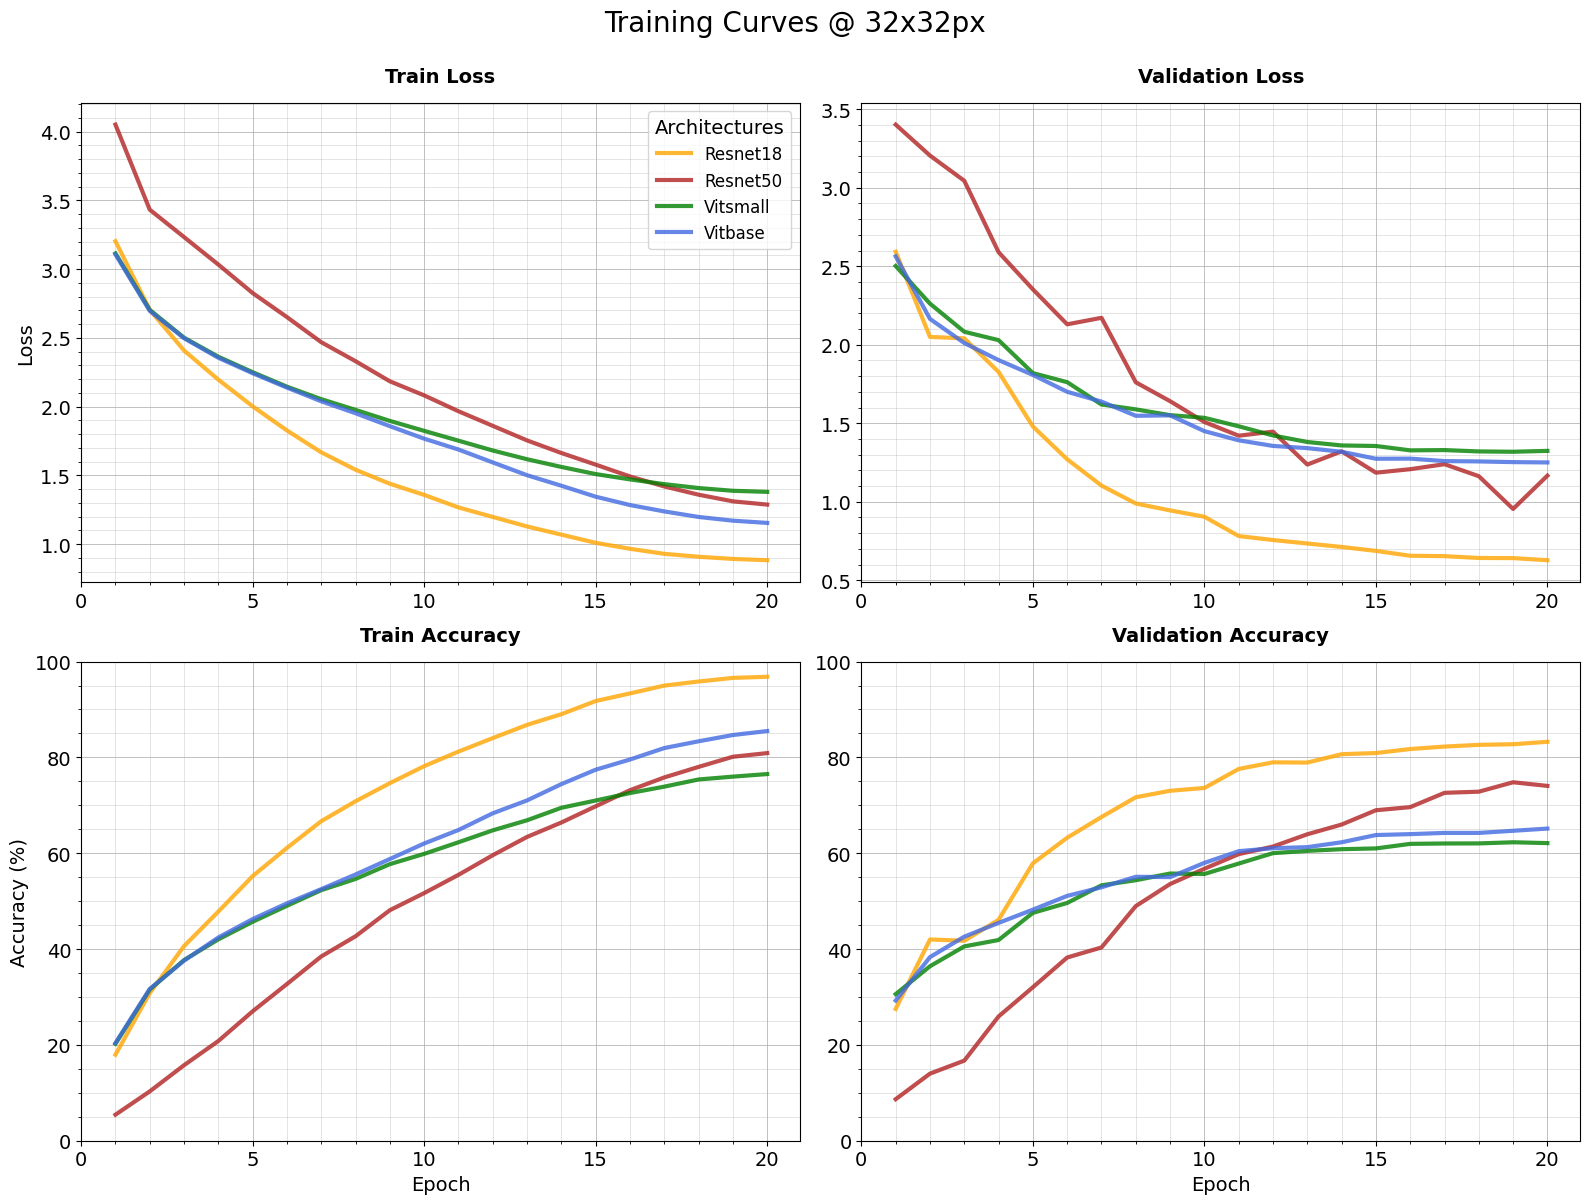

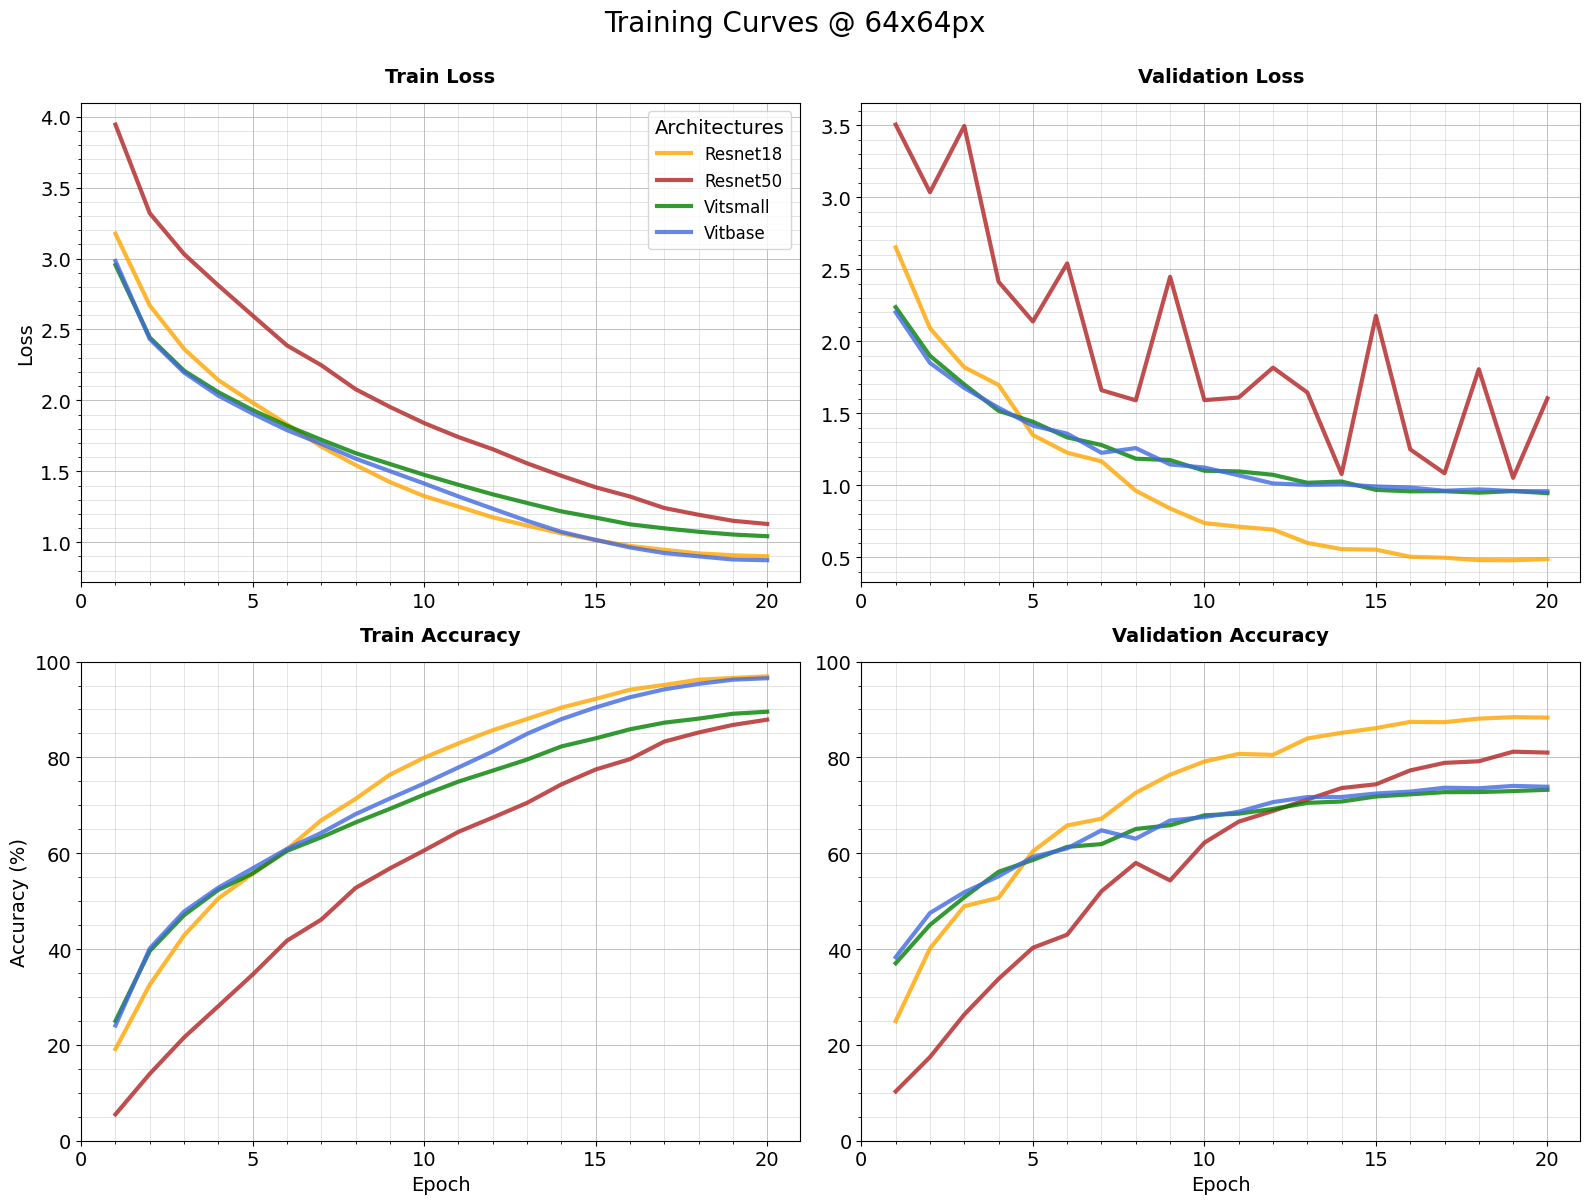

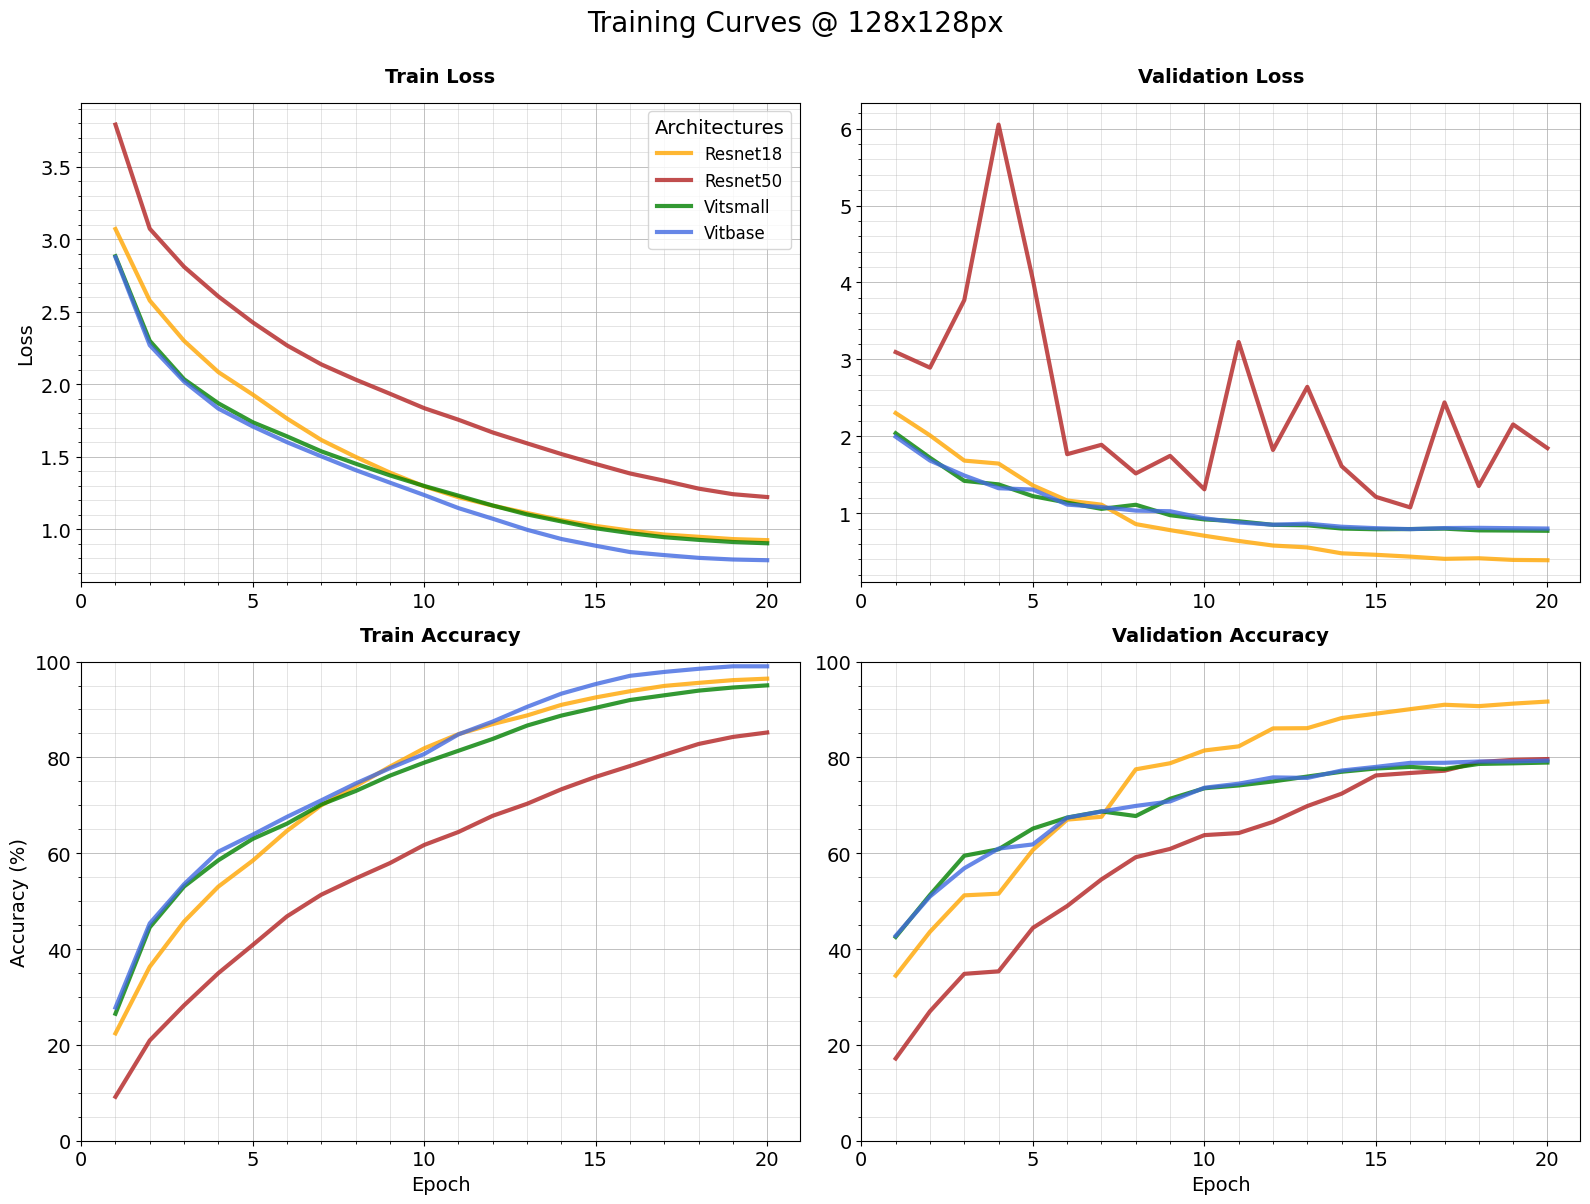

In [ ]:
# Styling colors
colors = {
    'resnet18': 'orange',
    'resnet50': 'firebrick',
    'vitsmall': 'green',
    'vitbase': 'royalblue'
}


# Display training curves (formatted) for each resolution for all models
for px_target in [32, 64, 128]:
    # Create matplotlib subplots (4 )
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True)
    fig.suptitle(f'Training Curves @ {px_target}x{px_target}px', fontsize=20, y=1)
    
    # Iterate over each model in result table
    for model_px_name, result_table in results_dict.items():
        # Get name and color formatting from architecture-pixel index
        arch, px = model_px_name.split('-')
        px = int(px)
        if px != px_target: # Skip model if its not at the current resolution iteration
            continue
        color = colors[arch]

        # Get training results for that model at that image resolution
        train_loss = result_table[1]
        val_loss = result_table[2]
        train_acc = result_table[3]
        val_acc = result_table[4]

        # Plot Train Loss
        sns.lineplot(ax=axes[0, 0], x=epochs, y=train_loss,
                     linewidth=3, color=color, linestyle='-', label=arch.title(), legend=False, alpha=0.8)
        axes[0, 0].set_title('Train Loss', fontsize=14, pad=15, fontweight='bold')
        axes[0, 0].set_ylabel('Loss', fontsize=14)
        axes[0, 0].legend(title='Architectures', fontsize=12, title_fontsize=14)

        # Plot Validation Loss
        sns.lineplot(ax=axes[0, 1], x=epochs, y=val_loss,
                     linewidth=3, color=color, linestyle='-', label=arch.title(), legend=False, alpha=0.8)
        axes[0, 1].set_title('Validation Loss', fontsize=14, pad=15, fontweight='bold')

        # Plot Train Accuracy
        sns.lineplot(ax=axes[1, 0], x=epochs, y=train_acc,
                     linewidth=3, color=color, linestyle='-', label=arch.title(), legend=False, alpha=0.8)
        axes[1, 0].set_title('Train Accuracy', fontsize=14, pad=15, fontweight='bold')
        axes[1, 0].set_ylabel('Accuracy (%)', fontsize=14)
        axes[1, 0].set_xlabel('Epoch', fontsize=14)
        axes[1, 0].set_ylim(0, 100)
        # Plot Validation Accuracy
        sns.lineplot(ax=axes[1, 1], x=epochs, y=val_acc,
                     linewidth=3, color=color, linestyle='-', label=arch.title(), legend=False, alpha=0.8)
        axes[1, 1].set_title('Validation Accuracy', fontsize=14, pad=15, fontweight='bold')
        axes[1, 1].set_xlabel('Epoch', fontsize=14)
        axes[1, 1].set_ylim(0, 100)

    
    # Formatting each axis
    for ax in axes.ravel():
        ax.margins(x=0.05)
        ax.minorticks_on()
        ax.grid(True, which='major', linewidth=0.7, alpha=0.8)
        ax.grid(True, which='minor', linewidth=0.4, alpha=0.6)
        ax.set_xticks(np.arange(0, num_epochs+1, 5))
        ax.tick_params(labelbottom=True, labelsize=10)
        ax.tick_params(axis='both', which='major', labelsize=14)
              
    
    # Display graphs
    plt.tight_layout()
    plt.show()

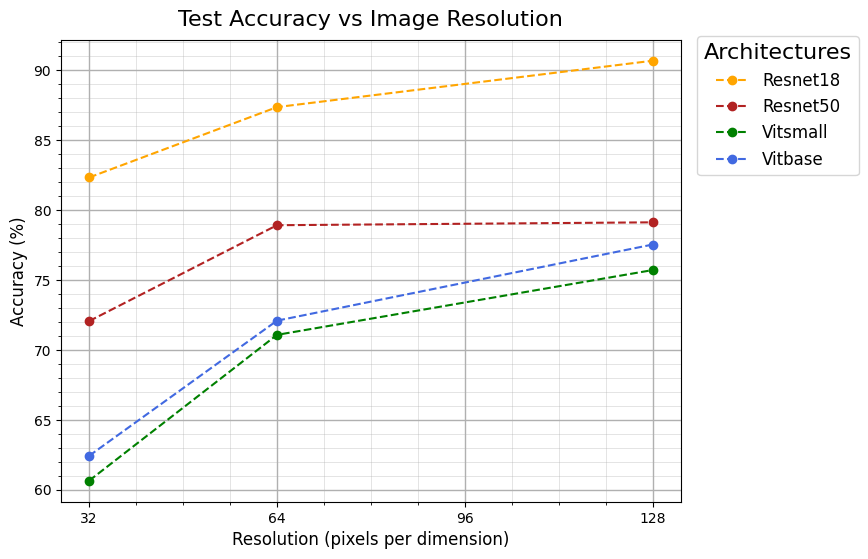

In [ ]:
# Plot testin results on one graph
pixels_list_graph = [32, 64, 96, 128]

colors = {
    'resnet18': 'orange',
    'resnet50': 'firebrick',
    'vitsmall': 'green',
    'vitbase': 'royalblue'
}

# Graph Accuracy vs Resolution
fig, ax = plt.subplots(figsize=(8,6))

# Iterate over each model testing results
for model_name, model_accs in architecture_accs.items():
    ax.plot(
        pixels_list,
        model_accs,
        label=model_name.title(),
        color=colors[model_name],
        linestyle='--',
        marker='o',
        markersize=6
    )

# Titles
ax.set_title('Test Accuracy vs Image Resolution', fontsize=16, pad=10)
ax.set_xlabel('Resolution (pixels per dimension)', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_xticks(pixels_list_graph) 

# Formatting each axis
ax.minorticks_on()
ax.grid(True, which='major', linewidth=1, alpha=1)
ax.grid(True, which='minor', linewidth=0.6, alpha=0.4)
fig.legend(loc='center left', bbox_to_anchor=(0.91, 0.77), fontsize=12, title='Architectures', title_fontsize=16)

# Display graph
plt.show()

In [ ]:
# Display the performance summary as a dataframe
df_perf_summary = pd.DataFrame(performance_summary_table, columns=['Model', 'Resolution', 'Loss', 'Accuracy', 'Precision', 'Recall', 
                                                                   'F1', 'Parameters', 'Training Time', 'Inference Time'])
display(df_perf_summary)

# Save the dataframe as a csv and export
df_perf_summary.to_csv('performance_table.csv', index=False)

,Model,Resolution,Loss,Accuracy,Precision,Recall,F1,Parameters,Training Time,Inference Time
0,Resnet18,32,0.666433,82.333333,0.823520,0.823333,0.822409,11191917,307,0.001681
1,Resnet18,64,0.519407,87.365079,0.874041,0.873651,0.873049,11191917,353,0.003994
2,Resnet18,128,0.429880,90.682540,0.908153,0.906825,0.906947,11191917,687,0.013433
3,Resnet50,32,1.071365,72.063492,0.722324,0.720635,0.718201,23592557,354,0.004150
4,Resnet50,64,0.977102,78.920635,0.790105,0.789206,0.787964,23592557,609,0.013128
5,Resnet50,128,2.152084,79.126984,0.795302,0.791270,0.790998,23592557,2087,0.061769
6,Vitsmall,32,1.387477,60.650794,0.609818,0.606508,0.603393,21392685,455,0.001994
7,Vitsmall,64,1.032715,71.079365,0.713579,0.710794,0.708631,21411117,475,0.005630
8,Vitsmall,128,0.884523,75.714286,0.760179,0.757143,0.756384,21484845,1305,0.022175
9,Vitbase,32,1.340176,62.428571,0.623447,0.624286,0.621687,85252653,499,0.005560


In [34]:
# Visualize the dat
train_loader, val_loader, test_loader, mean, stdev = create_resisc_dataloader(dataset, 128)
vit_small = results_dict['vitsmall-128'][0]

Extra code to visualize attention map for an input image

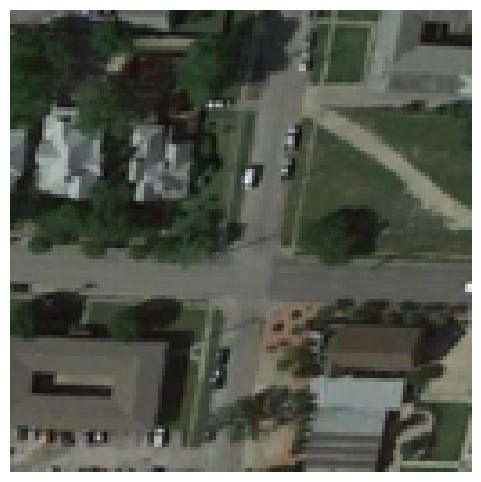

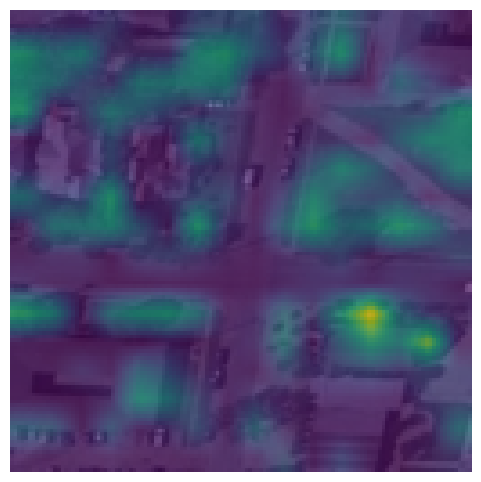

Predicted Class: tennis_court
Actual class: rectangular_farmland


In [35]:
import torch.nn.functional as F
import types

# Helper method to display image
def show_img(img):
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

# Helper method to display heatmap
def show_htmp(img, heatmap, alpha=0.7):
    # Ensures inputs are np.arrays for matplotlib
    if isinstance(img, torch.Tensor):
        img = img.cpu().numpy()
    if isinstance(heatmap, torch.Tensor):
        heatmap = heatmap.cpu().numpy()

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.imshow(heatmap, alpha=alpha) # Overlay heatmap
    plt.axis("off")
    plt.show()

# ViT attention hook -> Custom forward pass to extract attention maps
def forward_with_attn(self, input):
    # Forward pass with input image
    x = self.ln_1(input)

    # Compute self attention and return attention weights
    x, attn = self.self_attention(
        x, x, x,
        need_weights=True,
        average_attn_weights=False
    )

    # Save full attention map and attention from CLS toke
    self.attn_map = attn # [B, heads, N, N]
    self.cls_attn_map = attn[:,:,0,1:] # [B, heads, num_patches] CLS to patch attention

    # Add residual connection (already present in architecture)
    x = self.dropout(x)
    x = x + input
    
    # Feed-forward network (multi-layer perceptron, already present in architecture)
    y = self.ln_2(x)
    y = self.mlp(y)
    return (x + y)

# Get a batch from tthe dataloader
batch = next(iter(test_loader))
images = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

# Pick an image from the batch
img_idx = 31
x = images[img_idx]

# Attach attention hook to last transformer block
last_block = vit_small.encoder.layers[-1]
last_block.forward = types.MethodType(forward_with_attn, last_block)

# Run forward pass with no gradients to extract attention
with torch.no_grad():
    y = vit_small(x.unsqueeze(0))

# Get attention maps saved by the hook
attn = last_block.attn_map
cls = last_block.cls_attn_map

# Mean attention over heads (reduce noise)
attn = attn.mean(dim=1).squeeze(0) # Shape [N, N]
cls = cls.mean(dim=1).squeeze(0) # Shape [num_patches]

# Reshape CLS attention to patch grid
patch = vit_small.patch_size
img_size = vit_small.image_size
grid_size = img_size // patch
cls_2d = cls.view(grid_size, grid_size)

# Upsample attention map to image resolution
cls_resized = F.interpolate(
    cls_2d.unsqueeze(0).unsqueeze(0),
    size=(img_size, img_size),
    mode="bilinear",
    align_corners=False
).squeeze()


# Mean and standard deviation found earlier (used during data normalization)
mean = [0.36869990825653076, 0.3813214600086212, 0.3438914120197296]
std = [0.19506098330020905, 0.176242396235466, 0.17564313113689423]

# Unnormalize input image with mean and std for visualization
img_vis = x.cpu().permute(1,2,0) * torch.tensor(std) + torch.tensor(mean)
img_vis = img_vis.clamp(0,1)

# Display images and results
show_img(img_vis) # Display only the image
show_htmp(img_vis, cls_resized) # Overlay image and attention map
print(f'Predicted Class: {class_names[y.argmax().item()]}')
print(f'Actual class: {class_names[labels[img_idx].item()]}')